# Quantum generative adversarial learning in photonics — reproduction notebook

Wang et al., "Quantum generative adversarial learning in photonics", Optics Letters 48(20), 5197–5200 (2023), [DOI 10.1364/OL.505084](https://doi.org/10.1364/OL.505084), [arXiv:2310.00585v1](https://arxiv.org/abs/2310.00585v1).

How to run:
- Everything is simulated: no chip is available.
- Live cells call `lib/` and take about 1.5 minutes on a CPU.
- Paper-scale results (100 targets per point) come from `results/per_target_results.json`, exported from the validated runs.
- Run the notebook from `papers/qgan_quantum_data_photonics`.

## 1. Problem and claim

The quantum data to learn is a two-photon state, maximally entangled between two ququarts (4 + 4 path modes).
- **Generator:** two 15-phase-shifter meshes prepare $|g\rangle$.
- **Discriminator:** two 6-phase-shifter projection circuits pick the measurement that best separates $|g\rangle$ from the target $\tau$.
- The generator learns from that measured difference only.

| Claim | Paper evidence |
|---|---|
| Learning on a noisy chip: 16.96 % → 96.02 % root fidelity in 150 rounds | Fig. 2a–b (one chip run) |
| Phase-noise robustness: above 90 % for σ < 0.04π, below 80 % at 0.05π | Fig. 2c |
| Defect tolerance: above 90 % with up to about half of the 30 generator phase shifters stuck | Fig. 3b; Fig. 3a (chip, 16 stuck: 92.11 %) |
| Fewer counts degrade learning; no single stuck phase shifter matters | Suppl. Fig. 9, Suppl. Sec. 6 |

**Question:** does the QGAN keep a mean final root fidelity ≥ 0.90 for σ ≤ 0.03π and up to 14 of 30 stuck phase shifters?

**The claims would weaken if:**
- the fidelity fell below 0.90 there;
- a learner without the adversarial discriminator did as well;
- the decline with defects followed what the circuit can still express.

## 2. Data, metric and protocol

- **Data:** one target per seed, generated as in the paper: τ = (U ⊗ 1)|ψ0⟩ with U Haar-random.
  - The discriminator's start, the stuck phase shifters, the noise and the counts each come from their own stream of the seed (`lib/data.py`), so every condition sees the same targets.
  - There is no split, and nothing is selected on the evaluation targets (seeds 0–99). The training settings were chosen on seeds 1000–1019.
- **Metric:** the root fidelity $F = |\langle g|\tau\rangle|$, with the phases the generator intends to set.
  - Final value: the average over the last 20 rounds, then mean ± std over targets.
  - "Noise-averaged": $F$ averaged over 100 phase-noise draws.
- **Noise, the paper's models:** Gaussian phase noise on every phase shifter, redrawn at each execution; 1500 Poisson counts per measurement setting.

| Deviation or reduction | Likely impact |
|---|---|
| Training settings are ours, because the paper gives none: step 0.3π, up to 20 steps per turn, and the generator stops once the measured d ≤ 0.05. Calibrated on σ = 0.01π | High at large σ (section 10) |
| Haar targets, uniform starting phases and stuck values, equal defects per circuit (not stated in the paper) | Small (section 4) |
| Chip runs replayed in simulation at σ = 0.01π and 0.02π, on 20 targets (no chip) | Hardware values compared as trends only |
| One run per condition; 20 targets for the chip replays, the per-position check and the protocol diagnosis | Intervals cover the targets, not the noise draws |
| MerLin: uniform phase noise (same std), counts from our Poisson model, 5 of the 13 defect rates | Partly comparable with numpy (section 11) |

In [1]:
import json
import sys
import time
from pathlib import Path

START = time.perf_counter()
PAPER = Path.cwd()
assert (PAPER / "lib" / "runner.py").is_file(), (
    "run this notebook from papers/qgan_quantum_data_photonics"
)
REPO = PAPER.parents[1]
for path in (REPO, PAPER.parent, PAPER / "utils"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
import numpy as np
import paper_values as paper
from IPython.display import Markdown, display

from qgan_quantum_data_photonics.lib.circuits import (
    GENERATOR_LAYOUT,
    beam_splitter,
    circuit_unitaries,
    generated_amplitudes,
    generator_identity_phases,
    mzi_matrices,
    output_distribution,
    root_fidelity,
)
from qgan_quantum_data_photonics.lib.data import generate_inputs
from qgan_quantum_data_photonics.lib.metrics import shot_noise_tvd
from qgan_quantum_data_photonics.lib.qgan import train_qgan
from qgan_quantum_data_photonics.lib.runner import qgan_settings
from runtime_lib.config import deep_update, load_config

STORED = json.loads((PAPER / "results" / "per_target_results.json").read_text())
COLOR = {
    "QGAN": "#2a78d6",
    "noise-averaged": "#184f95",
    "paper": "#1baf7a",
    "ceiling": "#eda100",
    "noise-free": "#52514e",
    "MerLin": "#eb6834",
}
SIGMAS = (0.01, 0.02, 0.03, 0.04, 0.05)
STUCK = tuple(range(0, 25, 2))
TOLERANCE = 0.02  # tie tolerance in root fidelity, set before the comparisons


def config(overlay):
    # defaults.json, then the experiment's overlay, as the shared runtime does
    return deep_update(
        load_config(PAPER / "configs" / "defaults.json"),
        load_config(PAPER / "configs" / overlay),
    )


def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def per_target(sweep, run, key="final_fidelity"):
    return np.array(STORED[sweep][run][key])


def defect_run(stuck):
    sweep = "low" if stuck <= 8 else "mid" if stuck <= 16 else "high"
    return f"defect_rate_sweep_{sweep}", f"stuck_{stuck}_of_30"


def paired(values, reference):
    # Mean paired difference over targets, 95 % percentile bootstrap
    # (10,000 resamples, seed 0) and the decision rule with the 0.02 tolerance.
    diff = np.asarray(values) - np.asarray(reference)
    rng = np.random.default_rng(0)
    means = diff[rng.integers(0, diff.size, (10_000, diff.size))].mean(axis=1)
    low, high = np.percentile(means, [2.5, 97.5])
    mean = float(diff.mean())
    if abs(mean) <= TOLERANCE:
        outcome = "tied"
    elif low > 0 or high < 0:
        outcome = "clearly higher" if mean > 0 else "clearly lower"
    else:
        outcome = "no clear separation"
    return mean, low, high, outcome


def show_diff(result):
    mean, low, high, outcome = result
    return f"{mean:+.3f} [{low:+.3f}, {high:+.3f}], {outcome}"


fig2c = config("phase_noise_sweep_original.json")
settings = qgan_settings(fig2c)
print("Fig. 2c protocol:", {k: fig2c[k] for k in ("seeds", "noise", "evaluation")})
print(
    f"training: {settings.rounds} rounds, step {settings.learning_rate / np.pi:.2f}π, "
    f"up to {settings.steps_per_turn} steps per turn, generator stops at d ≤ "
    f"{settings.generator_stop_d}, parameter shift ±{settings.shift / np.pi:.2f}π"
)

inputs = generate_inputs([0, 1, 2], {"mode": "none"})
tau = inputs.target_amplitudes  # amplitude matrix: tau[s, i] for signal s, idler i
signal_state = tau @ tau.conj().transpose(0, 2, 1)
defective = generate_inputs([0, 1, 2], {"mode": "random_per_circuit", "count_per_circuit": 8})
print(
    f"targets {inputs.targets.shape}; norm error {np.abs(np.linalg.norm(inputs.targets, axis=1) - 1).max():.1e}; "
    f"signal state minus I/4: {np.abs(signal_state - np.eye(4) / 4).max():.1e} (maximally entangled)"
)
print(
    "8 stuck per circuit:", defective.stuck_mask.sum(axis=2).tolist(),
    "| same targets as without defects:", np.array_equal(defective.targets, inputs.targets),
)

Fig. 2c protocol: {'seeds': {'start': 0, 'count': 100}, 'noise': {'phase_sigma_pi': 0.01, 'counts': 1500, 'redraw': 'execution', 'tau_measurement': 'noisy'}, 'evaluation': {'eval_every': 50, 'noise_draws': 100, 'final_window': 20, 'convergence_tolerance': 0.01, 'fidelity_threshold': 0.9}}
training: 400 rounds, step 0.30π, up to 20 steps per turn, generator stops at d ≤ 0.05, parameter shift ±0.25π
targets (3, 16); norm error 2.2e-16; signal state minus I/4: 1.7e-16 (maximally entangled)
8 stuck per circuit: [[8, 8], [8, 8], [8, 8]] | same targets as without defects: True


## 3. The method in equations

- **Chip blocks** (Suppl. Eqs. 2–4): $BS = \tfrac{1}{\sqrt2}\begin{pmatrix}1 & i\\ i & 1\end{pmatrix}$, $PS(\theta) = \mathrm{diag}(e^{i\theta}, 1)$, $MZI(\theta) = BS\,PS(\theta)\,BS$.
- **Generator** (Eq. 3): $|g\rangle = (U_s \otimes U_i)|\psi_0\rangle$, with $|\psi_0\rangle = \tfrac12 \sum_k |k\rangle_s |k\rangle_i$.
- **Discriminator:** $M = P_s \otimes P_i$, "both photons leave port 2". So $\mathrm{tr}[M\rho]$ is a coincidence probability, estimated from counts.
- **Game** (Eqs. 1–2): the discriminator ascends and the generator descends $d = |\mathrm{tr}[M\rho] - \mathrm{tr}[M\tau]|$.
  - Gradients use the parameter-shift rule $\partial_\theta P = [P(\theta+\pi/4) - P(\theta-\pi/4)]/\sqrt2$, exact here because each phase shifter carries at most one photon.
  - Every shifted term is a separate noisy execution.
- **End of a turn (our rule):** $|a-b|$ has a kink at $a = b$, so a generator that keeps stepping drifts away. The generator therefore stops once the measured $d \le 0.05$ (section 5).

## 4. Checks with known answers

Five checks, each against an independent answer: the circuits, the gradient, the measurement bound, the start fidelity and the count model.

In [2]:
rng = np.random.default_rng(7)
theta = rng.uniform(0, 2 * np.pi, 50)
by_product = np.array([beam_splitter() @ np.diag([np.exp(1j * t), 1]) @ beam_splitter() for t in theta])
identity = circuit_unitaries(generator_identity_phases()[None], GENERATOR_LAYOUT)[0]

phases = rng.uniform(0, 2 * np.pi, 42)  # 15 + 15 generator, 6 + 6 discriminator


def port2_probability(p):
    p = np.atleast_2d(p)
    probs = output_distribution(generated_amplitudes(p[:, :15], p[:, 15:30]), p[:, 30:36], p[:, 36:])
    return probs[:, 1, 1]


shifted = np.repeat(phases[None], 4 * 42, axis=0)
for j in range(42):
    shifted[4 * j : 4 * j + 4, j] += [np.pi / 4, -np.pi / 4, 1e-6, -1e-6]
values = port2_probability(shifted).reshape(42, 4)
shift_rule = (values[:, 0] - values[:, 1]) / np.sqrt(2)
finite_difference = (values[:, 2] - values[:, 3]) / 2e-6

target = generate_inputs([0], {"mode": "none"}).target_amplitudes
projectors = rng.uniform(0, 2 * np.pi, (20_000, 12))
best_projector = output_distribution(np.repeat(target, 20_000, axis=0), projectors[:, :6], projectors[:, 6:])[:, 1, 1].max()

tvd = shot_noise_tvd([100, 10_000], repeats=1000, rng=np.random.default_rng(0))

haar = generate_inputs(list(range(10_000, 15_000)), {"mode": "none"})
start = np.tile(generator_identity_phases(), (5000, 1))
start_fidelity = root_fidelity(generated_amplitudes(start, start), haar.target_amplitudes)

table(
    ["Check", "Result", "Expected"],
    [
        ["MZI closed form − BS·PS·BS (50 phases)", f"{np.abs(mzi_matrices(theta) - by_product).max():.1e}", "0"],
        ["Identity setting of the mesh − I", f"{np.abs(identity - np.eye(4)).max():.1e}", "0"],
        ["Parameter shift − finite differences (42 phases)", f"{np.abs(shift_rule - finite_difference).max():.1e}", "≈ 0 (finite-difference error)"],
        ["Best tr[Mτ] over 20,000 random projectors", f"{best_projector:.4f}", "≤ 0.25"],
        ["Start fidelity, 5000 Haar targets (mean)", f"{start_fidelity.mean():.3f}", "chip run: 0.1696"],
        ["Share of targets starting below 0.1696", f"{(start_fidelity < 0.1696).mean():.0%}", "a typical start"],
        ["Count model: mean distance to a uniform 16-outcome distribution, 100 / 10,000 counts", f"{tvd[100]:.4f} / {tvd[10_000]:.4f}", "paper (Suppl. Fig. 9a): 0.155 / 0.016"],
    ],
)

| Check | Result | Expected |
|---|---|---|
| MZI closed form − BS·PS·BS (50 phases) | 3.7e-16 | 0 |
| Identity setting of the mesh − I | 2.4e-16 | 0 |
| Parameter shift − finite differences (42 phases) | 5.8e-11 | ≈ 0 (finite-difference error) |
| Best tr[Mτ] over 20,000 random projectors | 0.2421 | ≤ 0.25 |
| Start fidelity, 5000 Haar targets (mean) | 0.223 | chip run: 0.1696 |
| Share of targets starting below 0.1696 | 36% | a typical start |
| Count model: mean distance to a uniform 16-outcome distribution, 100 / 10,000 counts | 0.1572 / 0.0153 | paper (Suppl. Fig. 9a): 0.155 / 0.016 |

All checks agree:
- the closed forms and the shift rule, to rounding error;
- no projector sees more than 1/4 of an entangled target, which is the ≈0.25 ceiling of Fig. 2a;
- the chip's 16.96 % start is an ordinary draw;
- the count model gives the sampling error of Suppl. Fig. 9a within 0.003.

## 5. The pipeline, step by step

Five targets without noise, through `lib.qgan.train_qgan`, once with our end-of-turn rule and once with fixed 20-step turns. The game never uses the fidelity; it is shown here for monitoring only.

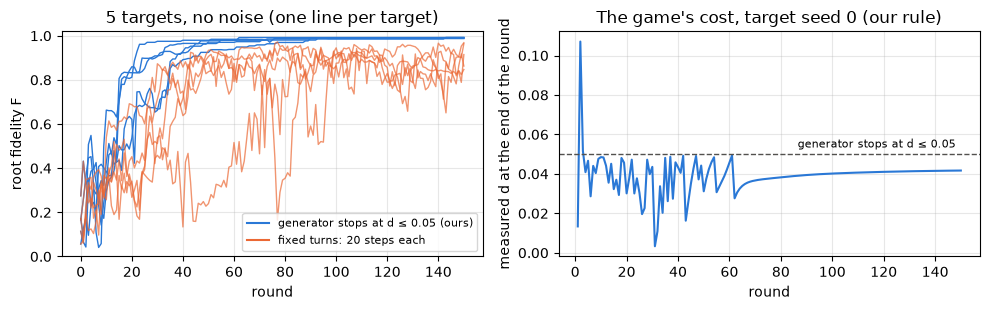

after 150 rounds, mean F over the 5 targets: 0.990 with our rule, 0.911 with fixed turns
largest change of F over the last 50 rounds, per target: at most 0.007 with our rule; 0.15 to 0.32 with fixed turns
final exact d without noise (mean over the 5 targets and the last 20 rounds): 0.044


In [3]:
walk_cfg = deep_update(config("noise_free_reference_original.json"), {"training": {"rounds": 150}})
walk_inputs = generate_inputs(list(range(5)), {"mode": "none"})
walkthrough = train_qgan(walk_inputs, qgan_settings(walk_cfg))
fixed_turns = train_qgan(
    walk_inputs, qgan_settings(deep_update(walk_cfg, {"training": {"generator_stop_d": None}}))
)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2))
left.plot(walkthrough.fidelity, color=COLOR["QGAN"], lw=1)
left.plot(fixed_turns.fidelity, color=COLOR["MerLin"], lw=1, alpha=0.7)
left.plot([], [], color=COLOR["QGAN"], label="generator stops at d ≤ 0.05 (ours)")
left.plot([], [], color=COLOR["MerLin"], label="fixed turns: 20 steps each")
left.set(xlabel="round", ylabel="root fidelity F", title="5 targets, no noise (one line per target)", ylim=(0, 1.02))
left.legend(fontsize=8, loc="lower right")
right.plot(np.arange(1, 151), walkthrough.d_measured[:, 0], color=COLOR["QGAN"])
right.axhline(0.05, color=COLOR["noise-free"], ls="--", lw=1)
right.text(148, 0.052, "generator stops at d ≤ 0.05", ha="right", va="bottom", fontsize=8)
right.set(xlabel="round", ylabel="measured d at the end of the round", title="The game's cost, target seed 0 (our rule)")
for ax in (left, right):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"after 150 rounds, mean F over the 5 targets: {walkthrough.fidelity[-1].mean():.3f} with our rule, {fixed_turns.fidelity[-1].mean():.3f} with fixed turns")
swing_ours = np.ptp(walkthrough.fidelity[-50:], axis=0)
swing_fixed = np.ptp(fixed_turns.fidelity[-50:], axis=0)
print(f"largest change of F over the last 50 rounds, per target: at most {swing_ours.max():.3f} with our rule; {swing_fixed.min():.2f} to {swing_fixed.max():.2f} with fixed turns")
print(f"final exact d without noise (mean over the 5 targets and the last 20 rounds): {walkthrough.d_exact[-20:].mean():.3f}")

- **Our rule:** the targets settle at 0.99; over the last 50 rounds, $F$ moves by at most 0.007.
- **Fixed turns:** the targets keep oscillating, by 0.15–0.32 over the last 50 rounds, and end at 0.911 on average.
- **Without noise:** the game ends at $d \approx 0.044$, just under the stop threshold.

## 6. A live experiment at full scale: σ = 0.05π

**Reproduction.** The paper's noisiest point of Fig. 2c (100 targets, 1500 counts, 400 rounds), where the paper reads 0.78. We rerun it live and compare it target by target with the stored run.

In [4]:
live_cfg = deep_update(config("phase_noise_sweep_original.json"), {"noise": {"phase_sigma_pi": 0.05}})
tic = time.perf_counter()
live = train_qgan(generate_inputs(list(range(100)), {"mode": "none"}), qgan_settings(live_cfg))
elapsed = time.perf_counter() - tic
live_final = live.fidelity[-20:].mean(axis=0)
live_averaged = live.noise_averaged[max(live.noise_averaged)]
stored_final = per_target("phase_noise_sweep", "sigma_0.05pi")
stored_averaged = per_target("phase_noise_sweep", "sigma_0.05pi", "noise_averaged_final_fidelity")
table(
    ["σ = 0.05π, 100 targets", "Final F (mean ± std)", "Noise-averaged", "Targets ≥ 0.90"],
    [
        [f"Live run ({elapsed:.0f} s)", f"{live_final.mean():.3f} ± {live_final.std(ddof=1):.3f}", f"{live_averaged.mean():.3f}", f"{(live_final >= 0.9).mean():.0%}"],
        ["Stored run of the sweep", f"{stored_final.mean():.3f} ± {stored_final.std(ddof=1):.3f}", f"{stored_averaged.mean():.3f}", f"{(stored_final >= 0.9).mean():.0%}"],
        ["Paper (read from Fig. 2c)", f"{paper.PHASE_NOISE_FINAL[0.05]:.2f}", "—", "—"],
    ],
)
print(f"largest per-target difference, live − stored: {np.abs(live_final - stored_final).max():.1e} (stored values rounded to 1e-6)")

| σ = 0.05π, 100 targets | Final F (mean ± std) | Noise-averaged | Targets ≥ 0.90 |
|---|---|---|---|
| Live run (76 s) | 0.962 ± 0.018 | 0.896 | 99% |
| Stored run of the sweep | 0.962 ± 0.018 | 0.896 | 99% |
| Paper (read from Fig. 2c) | 0.78 | — | — |

largest per-target difference, live − stored: 5.0e-07 (stored values rounded to 1e-6)


**Observation:** live and stored runs agree to the 1e-6 rounding. The mean is 0.962 (noise-averaged 0.896), against the paper's 0.78.

**Inference:** the stored sweep comes from this code. At the paper's noisiest level, our QGAN stays above 0.90.

**Remaining uncertainty:** the paper's training protocol, on which this point depends (section 10).

**Claim impact:** the drop below 0.80 at 0.05π does not reproduce with our protocol.

## 7. Headline results: Fig. 2c and Fig. 3b

**Reproduction**, from the stored runs, 100 targets per point:
- Fig. 2c: 400 rounds.
- Fig. 3b: σ = 0.02π, 2000 rounds, k stuck phase shifters drawn at random.

Blue is ours, green the paper; the horizontal line is the 0.90 threshold. The σ = 0.01π speed served for the calibration.

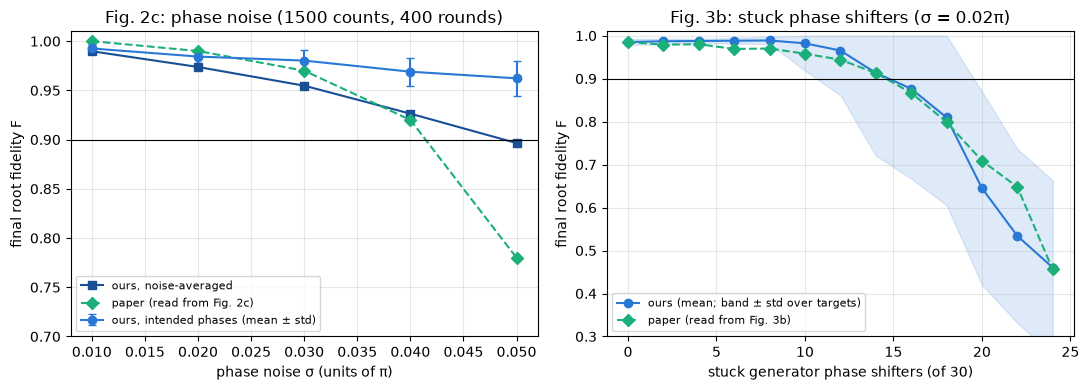

| σ | Ours | Ours, noise-averaged | Paper | Ours − paper |
|---|---|---|---|---|
| 0.01π | 0.993 ± 0.004 | 0.990 | 1.00 | -0.007 |
| 0.02π | 0.984 ± 0.007 | 0.974 | 0.99 | -0.006 |
| 0.03π | 0.980 ± 0.011 | 0.955 | 0.97 | +0.010 |
| 0.04π | 0.969 ± 0.014 | 0.926 | 0.92 | +0.049 |
| 0.05π | 0.962 ± 0.018 | 0.896 | 0.78 | +0.182 |

| Stuck / 30 | Ours | Targets ≥ 0.90 | Paper | Ours − paper |
|---|---|---|---|---|
| 0 | 0.985 ± 0.007 | 100% | 0.985 | +0.000 |
| 2 | 0.987 ± 0.006 | 100% | 0.979 | +0.008 |
| 4 | 0.988 ± 0.005 | 100% | 0.980 | +0.008 |
| 6 | 0.988 ± 0.006 | 100% | 0.969 | +0.019 |
| 8 | 0.989 ± 0.008 | 100% | 0.970 | +0.019 |
| 10 | 0.982 ± 0.063 | 98% | 0.958 | +0.024 |
| 12 | 0.965 ± 0.104 | 94% | 0.944 | +0.021 |
| 14 | 0.913 ± 0.192 | 85% | 0.913 | +0.000 |
| 16 | 0.877 ± 0.209 | 79% | 0.867 | +0.010 |
| 18 | 0.810 ± 0.204 | 50% | 0.799 | +0.011 |
| 20 | 0.645 ± 0.225 | 13% | 0.709 | -0.064 |
| 22 | 0.534 ± 0.203 | 4% | 0.648 | -0.114 |
| 24 | 0.460 ± 0.203 | 0% | 0.456 | +0.004 |

Rule, phase noise: mean ≥ 0.90 at every σ ≤ 0.03π: True
Rule, defects: mean ≥ 0.90 up to 14 of 30 stuck: True


| Chip run replayed (20 targets) | σ = 0.01π | σ = 0.02π | Paper, one chip run |
|---|---|---|---|
| Intact circuits, 150 rounds (Fig. 2b) | 0.989 ± 0.004 | 0.982 ± 0.009 | 0.9602 |
| 16 stuck as in Fig. 1(f), 160 rounds (Fig. 3a) | 0.940 ± 0.091 | 0.902 ± 0.127 | 0.9211 |

In [5]:
noise_rows, defect_rows = [], []
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
ours = [per_target("phase_noise_sweep", f"sigma_{s}pi") for s in SIGMAS]
averaged = [per_target("phase_noise_sweep", f"sigma_{s}pi", "noise_averaged_final_fidelity") for s in SIGMAS]
left.errorbar(SIGMAS, [v.mean() for v in ours], [v.std(ddof=1) for v in ours], marker="o", color=COLOR["QGAN"], capsize=3, label="ours, intended phases (mean ± std)")
left.plot(SIGMAS, [v.mean() for v in averaged], "s-", color=COLOR["noise-averaged"], label="ours, noise-averaged")
left.plot(SIGMAS, [paper.PHASE_NOISE_FINAL[s] for s in SIGMAS], "D--", color=COLOR["paper"], label="paper (read from Fig. 2c)")
for s, v, a in zip(SIGMAS, ours, averaged, strict=True):
    noise_rows.append([f"{s}π", f"{v.mean():.3f} ± {v.std(ddof=1):.3f}", f"{a.mean():.3f}", f"{paper.PHASE_NOISE_FINAL[s]:.2f}", f"{v.mean() - paper.PHASE_NOISE_FINAL[s]:+.3f}"])

defects = [per_target(*defect_run(k)) for k in STUCK]
means = np.array([v.mean() for v in defects])
spread = np.array([v.std(ddof=1) for v in defects])
right.plot(STUCK, means, "o-", color=COLOR["QGAN"], label="ours (mean; band ± std over targets)")
right.fill_between(STUCK, means - spread, np.minimum(means + spread, 1), color=COLOR["QGAN"], alpha=0.15)
right.plot(paper.DEFECT_STUCK, paper.DEFECT_FIDELITY, "D--", color=COLOR["paper"], label="paper (read from Fig. 3b)")
for k, v, p in zip(STUCK, defects, paper.DEFECT_FIDELITY, strict=True):
    defect_rows.append([k, f"{v.mean():.3f} ± {v.std(ddof=1):.3f}", f"{(v >= 0.9).mean():.0%}", f"{p:.3f}", f"{v.mean() - p:+.3f}"])
for ax, xlabel in ((left, "phase noise σ (units of π)"), (right, "stuck generator phase shifters (of 30)")):
    ax.axhline(0.9, color="k", lw=0.8)
    ax.set(xlabel=xlabel, ylabel="final root fidelity F")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")
left.set(title="Fig. 2c: phase noise (1500 counts, 400 rounds)", ylim=(0.7, 1.01))
right.set(title="Fig. 3b: stuck phase shifters (σ = 0.02π)", ylim=(0.3, 1.01))
plt.tight_layout()
plt.show()
table(["σ", "Ours", "Ours, noise-averaged", "Paper", "Ours − paper"], noise_rows)
table(["Stuck / 30", "Ours", "Targets ≥ 0.90", "Paper", "Ours − paper"], defect_rows)
print("Rule, phase noise: mean ≥ 0.90 at every σ ≤ 0.03π:", all(v.mean() >= 0.9 for s, v in zip(SIGMAS, ours) if s <= 0.03))
print("Rule, defects: mean ≥ 0.90 up to 14 of 30 stuck:", all(v.mean() >= 0.9 for k, v in zip(STUCK, defects) if k <= 14))
table(
    ["Chip run replayed (20 targets)", "σ = 0.01π", "σ = 0.02π", "Paper, one chip run"],
    [
        [name, *(f"{per_target('chip_emulations', f'{run}_sigma_{s}pi').mean():.3f} ± {per_target('chip_emulations', f'{run}_sigma_{s}pi').std(ddof=1):.3f}" for s in (0.01, 0.02)), value]
        for name, run, value in (
            ("Intact circuits, 150 rounds (Fig. 2b)", "intact_chip_emulation", "0.9602"),
            ("16 stuck as in Fig. 1(f), 160 rounds (Fig. 3a)", "defective_chip_emulation", "0.9211"),
        )
    ],
)

**Observation:**
- Up to σ = 0.03π we are within 0.01 of Fig. 2c. Above, we stay at 0.969 and 0.962, where the paper falls to 0.92 and 0.78.
- Fig. 3b is followed within 0.025 up to 18 stuck (0.913 at 14, as in the paper). We are 0.064 and 0.114 lower at 20 and 22.
- The chip replays reach 0.98–0.99 on intact circuits, and 0.90–0.94 with the chip's 16 stuck phase shifters (paper's chip: 0.9602 and 0.9211).

**Inference:** both claims hold at the paper's 0.90 threshold.

**Remaining uncertainty:**
- Paper values are read from figures (±0.01–0.02).
- The high-noise end depends on the protocol.
- Beyond 10 stuck, the targets spread widely (std up to 0.23): 79 % end above 0.90 at 16 stuck, 50 % at 18 and 13 % at 20.

**Claim impact:** defect tolerance is reproduced. Phase-noise robustness is reproduced below 0.04π, but not the drop at 0.05π.

## 8. Fair baselines

The paper has no baseline, and no classical generative model outputs a two-photon state. We compare the QGAN with other ways of setting the same chip, all planned before the runs:
- **Oracle ceiling:** direct maximization of the true fidelity, knowing τ. It is a bound, not a competitor.
- **Noise-free QGAN:** σ = 0 and exact probabilities.
- **Fixed discriminator:** random projectors (section 9).

| Dimension | Oracle ceiling | Noise-free QGAN | Fixed discriminator |
|---|---|---|---|
| Information | Knows τ (the QGAN sees only the measured d) | Same as the QGAN, without noise | Same as the QGAN |
| Parameters | Matched: the same 30 generator phases | Matched | Matched for the generator; no discriminator training |
| Training data | Matched: same targets and stuck sets | Matched | Matched |
| Optimization steps | Not matched: 20 restarts × 2000 exact-gradient steps | Matched | Matched for the generator |
| Tuning budget | Fixed before the runs | Matched (frozen settings) | Matched |
| Wall time per 100 targets | 0.5–0.6 min | 0.7 min, run alone (QGAN: 2.1–2.5 min, sharing the CPU) | 0.3 min |
| Evaluation | Same metric; under noise, both noise-averaged (100 and 1000 draws) | Matched | Matched |

**Decision rule** (set before the comparisons): two arms are **tied** when their mean paired difference is at most 0.02. They are **clearly** apart when it exceeds 0.02 and its 95 % interval excludes 0. The grey band in the figure is the tie band.

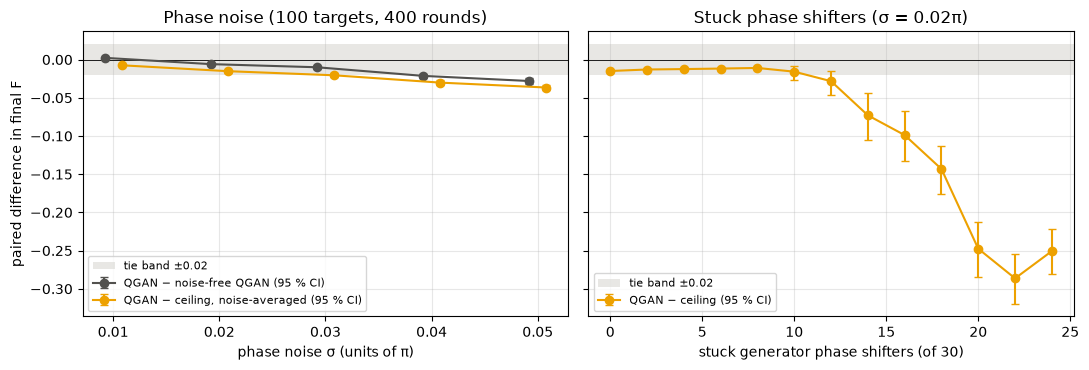

| σ | QGAN − noise-free | QGAN − ceiling (noise-averaged) |
|---|---|---|
| 0.01π | +0.002 [+0.001, +0.003], tied | -0.007 [-0.009, -0.006], tied |
| 0.02π | -0.006 [-0.007, -0.004], tied | -0.015 [-0.017, -0.013], tied |
| 0.03π | -0.010 [-0.012, -0.008], tied | -0.021 [-0.023, -0.018], clearly lower |
| 0.04π | -0.021 [-0.024, -0.019], clearly lower | -0.030 [-0.033, -0.027], clearly lower |
| 0.05π | -0.028 [-0.032, -0.025], clearly lower | -0.037 [-0.040, -0.033], clearly lower |

| Stuck / 30 | Ceiling (mean) | QGAN − ceiling |
|---|---|---|
| 0 | 1.000 | -0.015 [-0.016, -0.014], tied |
| 2 | 1.000 | -0.013 [-0.014, -0.012], tied |
| 4 | 1.000 | -0.012 [-0.014, -0.011], tied |
| 6 | 1.000 | -0.012 [-0.013, -0.011], tied |
| 8 | 1.000 | -0.011 [-0.012, -0.010], tied |
| 10 | 0.998 | -0.016 [-0.027, -0.009], tied |
| 12 | 0.994 | -0.028 [-0.046, -0.015], clearly lower |
| 14 | 0.986 | -0.073 [-0.105, -0.043], clearly lower |
| 16 | 0.975 | -0.099 [-0.133, -0.067], clearly lower |
| 18 | 0.953 | -0.143 [-0.176, -0.114], clearly lower |
| 20 | 0.893 | -0.248 [-0.284, -0.212], clearly lower |
| 22 | 0.820 | -0.286 [-0.319, -0.254], clearly lower |
| 24 | 0.711 | -0.251 [-0.281, -0.222], clearly lower |

noise-free QGAN, 400 rounds: 0.990 ± 0.003
largest gap to the generated results/baseline_comparison.json (23 comparisons): 9.5e-08


In [6]:
ceiling_intact = STORED["oracle_ceiling"]["ceiling_stuck_0_of_30"]["noise_averaged_best_fidelity"]
noise_free = per_target("noise_free_reference", "noise_free_400_rounds")
vs_noise_free = [paired(v, noise_free) for v in ours]
vs_ceiling_noise = [paired(a, ceiling_intact[str(s)]) for s, a in zip(SIGMAS, averaged, strict=True)]
vs_ceiling_defects = [
    paired(v, per_target("oracle_ceiling", f"ceiling_stuck_{k}_of_30", "best_fidelity"))
    for k, v in zip(STUCK, defects, strict=True)
]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, x, series in (
    (left, np.array(SIGMAS), ((vs_noise_free, "QGAN − noise-free QGAN", COLOR["noise-free"], -0.0008), (vs_ceiling_noise, "QGAN − ceiling, noise-averaged", COLOR["ceiling"], 0.0008))),
    (right, np.array(STUCK), ((vs_ceiling_defects, "QGAN − ceiling", COLOR["ceiling"], 0.0),)),
):
    ax.axhspan(-TOLERANCE, TOLERANCE, color="#d9d8d3", alpha=0.6, lw=0, label="tie band ±0.02")
    ax.axhline(0, color="k", lw=0.6)
    for results, label, color, offset in series:
        mean = np.array([r[0] for r in results])
        err = np.array([[r[0] - r[1] for r in results], [r[2] - r[0] for r in results]])
        ax.errorbar(x + offset, mean, err, marker="o", ls="-", color=color, capsize=3, label=label + " (95 % CI)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")
left.set(xlabel="phase noise σ (units of π)", ylabel="paired difference in final F", title="Phase noise (100 targets, 400 rounds)")
right.set(xlabel="stuck generator phase shifters (of 30)", title="Stuck phase shifters (σ = 0.02π)")
plt.tight_layout()
plt.show()

table(
    ["σ", "QGAN − noise-free", "QGAN − ceiling (noise-averaged)"],
    [[f"{s}π", show_diff(a), show_diff(b)] for s, a, b in zip(SIGMAS, vs_noise_free, vs_ceiling_noise, strict=True)],
)
table(
    ["Stuck / 30", "Ceiling (mean)", "QGAN − ceiling"],
    [[k, f"{per_target('oracle_ceiling', f'ceiling_stuck_{k}_of_30', 'best_fidelity').mean():.3f}", show_diff(r)] for k, r in zip(STUCK, vs_ceiling_defects, strict=True)],
)
print(f"noise-free QGAN, 400 rounds: {noise_free.mean():.3f} ± {noise_free.std(ddof=1):.3f}")

stored_table = {
    (r["control"], r["condition"]): r["difference"]["mean"]
    for r in json.loads((PAPER / "results" / "baseline_comparison.json").read_text())["comparisons"]
    if r["system"] == "QGAN"
}
gaps = [abs(a[0] - stored_table["Noise-free QGAN", f"sigma = {s}pi"]) for s, a in zip(SIGMAS, vs_noise_free, strict=True)]
gaps += [abs(a[0] - stored_table["Oracle ceiling", f"sigma = {s}pi"]) for s, a in zip(SIGMAS, vs_ceiling_noise, strict=True)]
gaps += [abs(a[0] - stored_table["Oracle ceiling", f"{k}/30 stuck"]) for k, a in zip(STUCK, vs_ceiling_defects, strict=True)]
print(f"largest gap to the generated results/baseline_comparison.json (23 comparisons): {max(gaps):.1e}")

**Observation:**
- Under phase noise, the QGAN is tied with both arms up to σ = 0.02π. It is then clearly below the ceiling from 0.03π (−0.021 to −0.037), and below the noise-free QGAN from 0.04π (−0.021 and −0.028).
- With defects, it is tied with the ceiling up to 10 stuck and clearly below from 12. The gap reaches −0.29 at 22, while the ceiling stays above 0.95 up to 18.

**Inference:**
- Up to 10 stuck phase shifters and σ = 0.02π, the QGAN reaches what the chip allows. Beyond that, learning, not the circuit, limits it.
- The noise-free QGAN plateaus at 0.990, slightly below the run at 0.01π. Its game ends just under the threshold (section 5). Our reading: a little noise keeps the generator stepping.

**Remaining uncertainty:** the noise-free reference depends on our turn rule, and there is one run per condition.

**Claim impact:** the paper claims no advantage over another method, and none is tested. Beyond 10 stuck, the tolerance to defects is limited by learning.

## 9. Controls and ablations

Three questions:
- Is the trained discriminator needed?
- Do the noise conventions the paper does not state change the results?
- Is any single phase shifter critical (Suppl. Sec. 6)?

In [7]:
qgan_002 = per_target("phase_noise_sweep", "sigma_0.02pi")
rows = [["Random projectors instead of the trained discriminator (σ = 0.02π)", show_diff(paired(per_target("single_runs", "fixed_discriminator"), qgan_002))]]
for s in SIGMAS:
    rows.append([f"tr[Mτ] computed exactly instead of measured (σ = {s}π)", show_diff(paired(per_target("phase_noise_variants", f"exact_tau_sigma_{s}pi"), per_target("phase_noise_sweep", f"sigma_{s}pi")))])
for s in (0.02, 0.04):
    rows.append([f"Noise drawn once per round instead of per execution (σ = {s}π)", show_diff(paired(per_target("phase_noise_variants", f"round_redraw_sigma_{s}pi"), per_target("phase_noise_sweep", f"sigma_{s}pi")))])
rows.append(["One stuck phase shifter per circuit against none (σ = 0.02π, 2000 rounds)", show_diff(paired(per_target("single_runs", "single_defect"), per_target(*defect_run(0))))])
table(["Control (paired over 100 targets)", "Difference [95 % CI], outcome"], rows)
positions = [per_target("single_defect_positions", f"position_{p}").mean() for p in range(15)]
print(f"each of the 15 positions stuck in both circuits (20 targets each): mean final F from {min(positions):.3f} to {max(positions):.3f}")
print("paper, Suppl. Sec. 6: 98.33 ± 7.00 % with one defect, 99.14 ± 1.23 % without")

| Control (paired over 100 targets) | Difference [95 % CI], outcome |
|---|---|
| Random projectors instead of the trained discriminator (σ = 0.02π) | -0.191 [-0.232, -0.152], clearly lower |
| tr[Mτ] computed exactly instead of measured (σ = 0.01π) | +0.001 [+0.000, +0.003], tied |
| tr[Mτ] computed exactly instead of measured (σ = 0.02π) | +0.002 [-0.000, +0.004], tied |
| tr[Mτ] computed exactly instead of measured (σ = 0.03π) | -0.000 [-0.003, +0.002], tied |
| tr[Mτ] computed exactly instead of measured (σ = 0.04π) | +0.006 [+0.002, +0.010], tied |
| tr[Mτ] computed exactly instead of measured (σ = 0.05π) | +0.000 [-0.004, +0.005], tied |
| Noise drawn once per round instead of per execution (σ = 0.02π) | +0.002 [-0.000, +0.003], tied |
| Noise drawn once per round instead of per execution (σ = 0.04π) | -0.001 [-0.004, +0.002], tied |
| One stuck phase shifter per circuit against none (σ = 0.02π, 2000 rounds) | +0.002 [+0.000, +0.004], tied |

each of the 15 positions stuck in both circuits (20 targets each): mean final F from 0.981 to 0.990
paper, Suppl. Sec. 6: 98.33 ± 7.00 % with one defect, 99.14 ± 1.23 % without


**Observation:**
- Random projectors lose 0.191.
- The two noise conventions move the results by at most 0.006, all tied.
- One stuck phase shifter per circuit is tied with none, and each position alone gives 0.981–0.990.

**Inference:** the trained discriminator matters, the high-noise gap does not come from these conventions, and no phase shifter is critical.

**Remaining uncertainty:** the ablation covers one condition (σ = 0.02π, intact circuits).

**Claim impact:** the single-defect claim is reproduced.

## 10. Robustness and uncertainty

Three views:
- every target of Fig. 3b;
- the training protocol at high noise: a **diagnosis** on 20 targets, one run per setting, changing one component at a time;
- the count budget (Suppl. Fig. 9b).

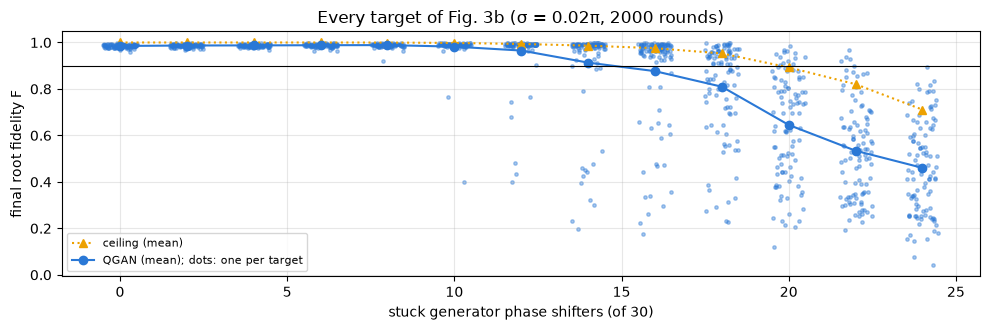

| Protocol (20 targets, one run each) | σ = 0.01π | σ = 0.03π | σ = 0.05π |
|---|---|---|---|
| calibrated protocol (main sweep, same 20 targets) | 0.993 ± 0.003 | 0.980 ± 0.014 | 0.965 ± 0.015 |
| generator stops at d ≤ 0.03 | 0.986 ± 0.006 | 0.957 ± 0.013 | 0.928 ± 0.044 |
| generator stops at d ≤ 0.01 | 0.956 ± 0.019 | 0.898 ± 0.044 | 0.827 ± 0.069 |
| step 0.5π | — | 0.967 ± 0.015 | 0.945 ± 0.016 |
| 10 steps per turn | — | 0.962 ± 0.023 | 0.940 ± 0.029 |
| paper (read from Fig. 2c) | 1.00 | 0.97 | 0.78 |

generator stops at d ≤ 0.01, σ = 0.05π, averaged over phase-noise draws: 0.782


| Counts (σ = 0, 2500 rounds) | QGAN | Paper | QGAN − noise-free |
|---|---|---|---|
| 100 | 0.961 | 0.921 | -0.030 [-0.034, -0.027], clearly lower |
| 200 | 0.980 | 0.987 | -0.011 [-0.013, -0.009], tied |
| 300 | 0.986 | 0.990 | -0.004 [-0.006, -0.003], tied |
| 400 | 0.989 | 0.989 | -0.002 [-0.003, -0.001], tied |
| 500 | 0.992 | 0.989 | +0.001 [+0.000, +0.002], tied |
| 1000 | 0.997 | 0.986 | +0.006 [+0.006, +0.007], tied |
| 1500 | 0.998 | 0.989 | +0.007 [+0.007, +0.008], tied |
| 2000 | 0.998 | 0.990 | +0.007 [+0.007, +0.008], tied |

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for k, v in zip(STUCK, defects, strict=True):
    ax.scatter(np.full(v.size, k) + np.random.default_rng(k).uniform(-0.5, 0.5, v.size), v, s=6, color=COLOR["QGAN"], alpha=0.4)
ax.plot(STUCK, [per_target("oracle_ceiling", f"ceiling_stuck_{k}_of_30", "best_fidelity").mean() for k in STUCK], "^:", color=COLOR["ceiling"], label="ceiling (mean)")
ax.plot(STUCK, means, "o-", color=COLOR["QGAN"], label="QGAN (mean); dots: one per target")
ax.axhline(0.9, color="k", lw=0.8)
ax.set(xlabel="stuck generator phase shifters (of 30)", ylabel="final root fidelity F", title="Every target of Fig. 3b (σ = 0.02π, 2000 rounds)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

main_020 = {s: per_target("phase_noise_sweep", f"sigma_{s}pi")[:20] for s in (0.01, 0.03, 0.05)}
diagnosis = [
    ("calibrated protocol (main sweep, same 20 targets)", {s: v for s, v in main_020.items()}),
    ("generator stops at d ≤ 0.03", {s: per_target("phase_noise_diagnosis", f"stop_0.03_sigma_{s}pi") for s in (0.01, 0.03, 0.05)}),
    ("generator stops at d ≤ 0.01", {s: per_target("phase_noise_diagnosis", f"stop_0.01_sigma_{s}pi") for s in (0.01, 0.03, 0.05)}),
    ("step 0.5π", {s: per_target("phase_noise_diagnosis", f"step_0.5pi_sigma_{s}pi") for s in (0.03, 0.05)}),
    ("10 steps per turn", {s: per_target("phase_noise_diagnosis", f"steps_10_sigma_{s}pi") for s in (0.03, 0.05)}),
]
table(
    ["Protocol (20 targets, one run each)", "σ = 0.01π", "σ = 0.03π", "σ = 0.05π"],
    [[name] + [f"{runs[s].mean():.3f} ± {runs[s].std(ddof=1):.3f}" if s in runs else "—" for s in (0.01, 0.03, 0.05)] for name, runs in diagnosis]
    + [["paper (read from Fig. 2c)", "1.00", "0.97", "0.78"]],
)
strict = per_target("phase_noise_diagnosis", "stop_0.01_sigma_0.05pi", "noise_averaged_final_fidelity")
print(f"generator stops at d ≤ 0.01, σ = 0.05π, averaged over phase-noise draws: {strict.mean():.3f}")

noise_free_2500 = per_target("noise_free_reference", "noise_free_2500_rounds")
table(
    ["Counts (σ = 0, 2500 rounds)", "QGAN", "Paper", "QGAN − noise-free"],
    [[n, f"{per_target('shot_noise_sweep', f'counts_{n}').mean():.3f}", f"{p:.3f}", show_diff(paired(per_target("shot_noise_sweep", f"counts_{n}"), noise_free_2500))] for n, p in zip(paper.SHOT_COUNTS, paper.SHOT_FIDELITY, strict=True)],
)

**Observation:**
- From 12 stuck, the targets split: some end near 1, others far below, even where the ceiling is above 0.95.
- A generator that stops only at d ≤ 0.01 drops to 0.827 at 0.05π (0.782 noise-averaged, the paper's value). But it is lower at small σ (0.956 at 0.01π), and no tested setting reproduces the whole curve.
- Only 100 counts fall clearly below the noise-free QGAN (−0.030).

**Inference:**
- The decline with defects is a growing failure rate on some targets, not a uniform loss.
- The paper's drop at 0.05π is consistent with a stricter or slower protocol than ours.

**Remaining uncertainty:**
- The paper's protocol and fidelity convention; the 0.782 match may be a coincidence.
- The diagnosis uses 20 targets.

**Claim impact:**
- Phase-noise robustness: partially reproduced.
- Shot noise: the trend is reproduced, but not its size at 100 counts (paper ≈0.92).

## 11. Photonic assessment: the chip as a MerLin layer

**Adaptation**, simulated. The chip is one MerLin `QuantumLayer`, built from a Perceval circuit:
- 8 modes, with 2 photons in the entangled `StateVector` input;
- 42 phases set at every execution;
- threshold detection in the `UNBUNCHED` space, which is exact here because each 4-mode block holds one photon.

Noise is either injected from the numpy draws (for an exact check) or MerLin's own `phase_error` (uniform, same std).

In [9]:
import warnings

from qgan_quantum_data_photonics.lib.qgan_merlin import MerlinHardware, build_chip_layer, chip_probabilities, coincidence_index

# Building the layer triggers torch's "Sparse invariant checks are implicitly disabled"
# warning inside MerLin (reported to the MerLin team); it does not affect the results.
warnings.filterwarnings("ignore", message="Sparse invariant checks", category=UserWarning)
layer = build_chip_layer()
index = coincidence_index(layer)
random_phases = np.random.default_rng(3).uniform(0, 2 * np.pi, (40, 42))
merlin_probs = chip_probabilities(layer, random_phases, index)
numpy_probs = output_distribution(generated_amplitudes(random_phases[:, :15], random_phases[:, 15:30]), random_phases[:, 30:36], random_phases[:, 36:])
print(f"layer outputs: {layer.output_size} UNBUNCHED patterns, 16 read as coincidences; MerLin − numpy on 40 random settings: {np.abs(merlin_probs - numpy_probs).max():.1e}")

check_inputs = generate_inputs([0, 1, 2], {"mode": "random_per_circuit", "count_per_circuit": 3})
check_settings = qgan_settings(deep_update(config("phase_noise_sweep_original.json"), {"training": {"rounds": 15}}))
numpy_run = train_qgan(check_inputs, check_settings)
merlin_run = train_qgan(check_inputs, check_settings, MerlinHardware(check_inputs, check_settings, "injected"))
print(f"15 rounds, 3 targets, 6 stuck, σ = 0.01π, same noise draws: largest fidelity difference {np.abs(numpy_run.fidelity - merlin_run.fidelity).max():.1e}")

rows = []
for s in SIGMAS:
    rows.append([f"σ = {s}π", show_diff(paired(per_target("merlin_native_phase_noise", f"merlin_phase_error_sigma_{s}pi"), per_target("phase_noise_sweep", f"sigma_{s}pi")))])
for k in (0, 8, 14, 16, 20):
    rows.append([f"{k} / 30 stuck, σ = 0.02π", show_diff(paired(per_target("merlin_native_defects", f"merlin_phase_error_stuck_{k}_of_30"), per_target(*defect_run(k))))])
table(["MerLin noise − numpy (100 targets, stored runs)", "Difference [95 % CI], outcome"], rows)
identical = [np.array_equal(per_target("merlin_equivalence", f"merlin_injected_{c}"), per_target(*r)) for c, r in (("sigma_0.01pi", ("phase_noise_sweep", "sigma_0.01pi")), ("sigma_0.05pi", ("phase_noise_sweep", "sigma_0.05pi")), ("stuck_16_of_30", defect_run(16)))]
print("stored runs with the same noise draws, every target identical (σ = 0.01π, 0.05π, 16/30 stuck):", identical)
hardware = STORED["merlin_native_defects"]["merlin_phase_error_stuck_16_of_30"]["hardware"]
table(["Hardware field", "Value"], [[k.replace("_", " "), v] for k, v in hardware.items() if k not in ("framework", "merlin_phase_error_half_width_rad")] + [["framework", "merlinquantum 0.4.2 (reports merlin.__version__ 0.4.1, the label stored in the runs), perceval 1.3.1"]])

layer outputs: 28 UNBUNCHED patterns, 16 read as coincidences; MerLin − numpy on 40 random settings: 3.1e-16


15 rounds, 3 targets, 6 stuck, σ = 0.01π, same noise draws: largest fidelity difference 0.0e+00


| MerLin noise − numpy (100 targets, stored runs) | Difference [95 % CI], outcome |
|---|---|
| σ = 0.01π | -0.001 [-0.002, +0.000], tied |
| σ = 0.02π | +0.000 [-0.002, +0.002], tied |
| σ = 0.03π | -0.003 [-0.006, +0.000], tied |
| σ = 0.04π | -0.003 [-0.007, +0.002], tied |
| σ = 0.05π | -0.015 [-0.021, -0.009], tied |
| 0 / 30 stuck, σ = 0.02π | -0.001 [-0.004, +0.001], tied |
| 8 / 30 stuck, σ = 0.02π | -0.001 [-0.003, +0.001], tied |
| 14 / 30 stuck, σ = 0.02π | +0.001 [-0.013, +0.017], tied |
| 16 / 30 stuck, σ = 0.02π | +0.021 [+0.001, +0.042], clearly higher |
| 20 / 30 stuck, σ = 0.02π | -0.022 [-0.058, +0.013], no clear separation |

stored runs with the same noise draws, every target identical (σ = 0.01π, 0.05π, 16/30 stuck): [True, True, True]


| Hardware field | Value |
|---|---|
| computation space | UNBUNCHED |
| detector model | threshold (at most one photon per 4-mode block, so equal to number resolution here) |
| encoding | 42 phase shifters as per-call input parameters (30 generator, 12 discriminator) |
| gradient | parameter shift (pi/4), each shifted term a separate noisy execution |
| input state | 1/2 (|10001000> + |01000100> + |00100010> + |00010001>) (signal modes 0-3, idler 4-7) |
| measurement strategy | MeasurementStrategy.probs(computation_space=UNBUNCHED); tr[M rho] = P(signal port 2, idler port 2) |
| noise mode | phase_error |
| number of modes | 8 |
| photon number | 2 |
| postselection | one photon per block; no probability leaves the 16 coincidence patterns (block-diagonal circuit) |
| shot count | 1500 |
| simulator | MerLin CPU analytic simulator (float64); counts drawn from its exact probabilities |
| tau measurement | tau prepared on the chip by the generator meshes (phases solved by least squares) |
| framework | merlinquantum 0.4.2 (reports merlin.__version__ 0.4.1, the label stored in the runs), perceval 1.3.1 |

**Observation:**
- MerLin equals the numpy chip to rounding error. With the same noise draws, every target ends identical, live and stored.
- With MerLin's own noise, the means stay tied at every σ and at 0, 8 and 14 stuck. At 16 and 20 stuck they fall just outside the band: +0.021 (clearly higher) and −0.022 (no clear separation). The targets spread widely there.

**Inference:** MerLin represents this chip exactly, and both robustness claims keep their outcome under its noise model.

**Remaining uncertainty:**
- The chip is ideal (lossless, ideal detectors); this is not hardware.
- The uniform noise and the noisy preparation of τ change together.
- 5 of the 13 defect rates were run.

**Claim impact:** the photonic adaptation succeeds (`MERLIN_IMPLEMENTATION`), in simulation.

## 12. Conclusion

- The software runs, and the method learns (sections 4–6).
- The paper's metric reproduces in part (section 7).
- The paper's explanation survives the controls (section 9).
- There is no competitor to beat (section 8).

1. **Reproduced:**
   - above 90 % for σ < 0.04π, within 0.01 of Fig. 2c up to 0.03π (section 7);
   - above 90 % up to 14 of 30 stuck, following Fig. 3b within 0.025 up to 18 (section 7);
   - no crucial phase shifter (section 9);
   - the sampling error of Suppl. Fig. 9a (section 4);
   - learning, in the chip replays (section 7).
2. **Not reproduced:**
   - the drop to 0.78 at σ = 0.05π; ours is 0.962 (sections 6–7);
   - the size of the drop at 100 counts (section 10);
   - the values at 20 and 22 stuck (section 7).
3. **Unresolved:** the paper's training protocol and fidelity convention (section 10).
4. **Not attempted:** chip measurements, tomography-based comparisons, MerLin with loss or detector models.
5. **Reproduction verdict:** partially reproduced in simulation.
   - The QGAN keeps the paper's robustness at its 90 % thresholds, without the high-noise drop.
   - Up to 10 stuck phase shifters and σ = 0.02π it reaches what the chip allows; beyond that, learning limits it (section 8).
6. **Photonic verdict:** the chip built as a MerLin layer gives identical results with the same noise draws, and the claims keep their outcome under MerLin's noise (section 11). This is a simulation, not hardware.

**Limitations:**
- simulation only;
- calibrated training settings;
- one run per condition;
- 20 targets for the chip replays and the diagnosis;
- an ablation in one condition;
- MerLin on 5 of the 13 defect rates;
- paper values read from figures.

In [10]:
print(f"Notebook run time: {(time.perf_counter() - START) / 60:.1f} min")

Notebook run time: 1.4 min
